<a href="https://colab.research.google.com/github/anupbagale/Image_Processing/blob/main/notebooks/11_huffman_coding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Huffman coding

Huffman coding gives short bit codes to common symbols and longer codes to rare ones. It builds a
binary tree from the symbol frequencies:

1. Start with one node per symbol, weighted by how often it appears.
2. Take the two nodes with the smallest weights and join them under a new node whose weight is
   their sum.
3. Repeat until only one node is left. That node is the root.

Each symbol's code is the path from the root to it, with 0 for a left branch and 1 for a right
branch. No code is the beginning of another code, so an encoded bit string can be decoded without
separators.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["image.cmap"] = "gray"
import heapq
from collections import Counter

## Building the tree and the codes

In [2]:
class Node:
    def __init__(self, symbol, freq, left=None, right=None):
        self.symbol = symbol
        self.freq = freq
        self.left = left
        self.right = right

    def __lt__(self, other):          # lets heapq compare nodes by frequency
        return self.freq < other.freq


def build_tree(frequencies):
    heap = [Node(symbol, freq) for symbol, freq in frequencies.items()]
    heapq.heapify(heap)
    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)
        heapq.heappush(heap, Node(None, left.freq + right.freq, left, right))
    return heap[0]


def make_codes(root):
    codes = {}

    def walk(node, code):
        if node.symbol is not None:
            codes[node.symbol] = code or "0"   # a tree with one symbol still needs one bit
            return
        walk(node.left, code + "0")
        walk(node.right, code + "1")

    walk(root, "")
    return codes


def encode(symbols, codes):
    return "".join(codes[s] for s in symbols)


def decode(bits, root):
    if root.symbol is not None:            # only one distinct symbol
        return [root.symbol] * len(bits)
    out, node = [], root
    for bit in bits:
        node = node.left if bit == "0" else node.right
        if node.symbol is not None:
            out.append(node.symbol)
            node = root
    return out

The first version of `make_codes` used a dictionary as a default argument (`codes={}`). Python
creates that dictionary only once, so codes from one call leaked into the next. Here the
dictionary is created inside the function on every call.

## Text

In [3]:
text = "Hello, how are you?"
frequencies = Counter(text)
root = build_tree(frequencies)
codes = make_codes(root)

for symbol, code in sorted(codes.items(), key=lambda kv: (len(kv[1]), kv[1])):
    print(f"{symbol!r:6} appears {frequencies[symbol]}x   code {code}")

bits = encode(text, codes)
decoded = "".join(decode(bits, root))
print()
print("encoded:", bits)
print("decoded:", decoded)
print(f"{len(text) * 8} bits as 8-bit characters -> {len(bits)} bits")

'e'    appears 2x   code 001
'o'    appears 3x   code 110
' '    appears 3x   code 111
'y'    appears 1x   code 0000
','    appears 1x   code 0001
'h'    appears 1x   code 0100
'?'    appears 1x   code 0101
'r'    appears 1x   code 0110
'a'    appears 1x   code 0111
'u'    appears 1x   code 1000
'H'    appears 1x   code 1001
'w'    appears 1x   code 1010
'l'    appears 2x   code 1011

encoded: 10010011011101111000011110100110101011101110110001111000011010000101
decoded: Hello, how are you?
152 bits as 8-bit characters -> 68 bits


The most common characters, `o` and the space, get 3-bit codes, and most characters that appear
once get 4 bits. Huffman codes are not unique when several symbols have the same frequency, so `l`
ends up with 4 bits even though it appears twice. The total length is the same for every valid
Huffman code.

## Images

The same code works on pixel values. The symbols are now the 256 grey levels, and each pixel
normally takes 8 bits.

In [4]:
def entropy(image):
    p = np.bincount(image.ravel(), minlength=256) / image.size
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p))) + 0.0   # + 0.0 turns -0.0 into 0.0


def huffman_image(name, image):
    pixels = image.ravel().tolist()
    frequencies = Counter(pixels)
    root = build_tree(frequencies)
    codes = make_codes(root)
    bits = encode(pixels, codes)
    restored = np.array(decode(bits, root), dtype=np.uint8).reshape(image.shape)

    avg = len(bits) / image.size
    print(f"{name:<8} entropy {entropy(image):.3f}   average code length {avg:.3f} bits/pixel   "
          f"size {image.size * 8 / len(bits):.2f}x smaller   lossless: {np.array_equal(restored, image)}")
    return codes, frequencies


camera_codes, camera_freq = huffman_image("camera", data.camera())
huffman_image("moon", data.moon())
huffman_image("coins", data.coins());

camera   entropy 7.232   average code length 7.262 bits/pixel   size 1.10x smaller   lossless: True
moon     entropy 4.885   average code length 4.925 bits/pixel   size 1.62x smaller   lossless: True
coins    entropy 7.524   average code length 7.549 bits/pixel   size 1.06x smaller   lossless: True


The average code length is always slightly above the entropy from notebook 09, never below it.
Entropy is the limit for any code that encodes pixels one at a time, and Huffman coding gets
within one bit of it (here much closer). The moon image compresses best because its grey levels
are concentrated in a narrow range.

The plot shows the histogram of the camera image above the code length of each grey level. The
most common grey levels get the shortest codes.

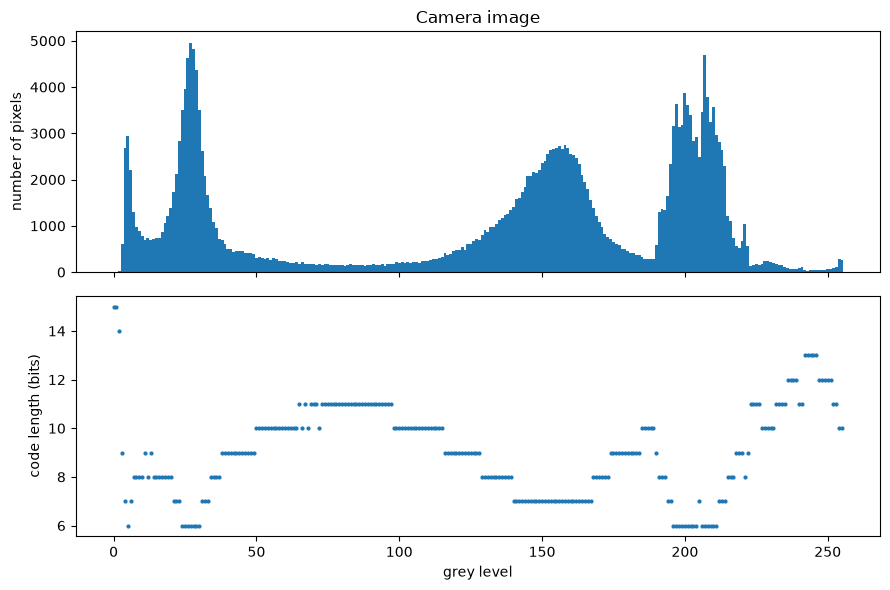

In [5]:
levels = np.array(sorted(camera_codes))
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].bar(levels, [camera_freq[v] for v in levels], width=1)
ax[0].set_ylabel("number of pixels")
ax[0].set_title("Camera image")
ax[1].plot(levels, [len(camera_codes[v]) for v in levels], ".", markersize=4)
ax[1].set_ylabel("code length (bits)")
ax[1].set_xlabel("grey level")
plt.tight_layout()
plt.show()